In [10]:
# Imports and file paths
import librosa
import pretty_midi
import numpy as np
import matplotlib.pyplot as plt


MAESTRO_DATASET_PATH = r"D:\IIT\4th Year\FYP\DATASETS\maestro-v3.0.0-midi\maestro-v3.0.0\\"
MIDI_FILE = r"2017\MIDI-Unprocessed_052_PIANO052_MID--AUDIO-split_07-06-17_Piano-e_3-03_wav--5.midi"
WAV_FILE = r"test_data\MIDI-Unprocessed_052_PIANO052_MID--AUDIO-split_07-06-17_Piano-e_3-03_wav--5.wav"

midi_path  = MAESTRO_DATASET_PATH + MIDI_FILE
audio_path = WAV_FILE

In [11]:
# Derive targets from the MIDI file
# (only done during training, not at prediction time)

midi = pretty_midi.PrettyMIDI(midi_path)

# Dynamic target: note velocity over time
times = []
velocities = []
for instrument in midi.instruments:
    for note in instrument.notes:
        times.append(note.start)
        velocities.append(note.velocity)

sorted_pairs = sorted(zip(times, velocities))
times, velocities = zip(*sorted_pairs)
times = np.array(times)
velocities = np.array(velocities)

# smooth into a continous dynamics curve
from scipy.ndimage import uniform_filter1d
time_grid = np.linspace(0, times[-1], 500)
velocity_grid = np.interp(time_grid, times, velocities)
dynamics_curve = uniform_filter1d(velocity_grid, size=20)

# tempo target: local BPM over time
tempo_times, tempos = midi.get_tempo_changes()
print(f"Tempo changes found: {len(tempo_times)}")
for t, bpm in zip(tempo_times, tempos):
    print(f"Time: {t:.2f} s, BPM: {bpm:.1f}")

Tempo changes found: 1
Time: 0.00 s, BPM: 120.0


In [13]:
from pathlib import Path

# Process audio only (model input at prediction time)
audio_file = Path(WAV_FILE).expanduser().resolve()
if not audio_file.is_file():
    raise FileNotFoundError(
        f"Audio file not found: {audio_file}\n"
        f"Notebook kernel working directory: {Path.cwd()}\n"
        "Set WAV_FILE to the actual location of the WAV file."
    )

print("\nLoading audio...")
y, sr = librosa.load(str(audio_file), sr=22050, mono=True)
print(f"Audio loaded - Duration: {len(y)/sr:.1f}s | Sample rate: {sr}Hz")

# convert to mel spectrogram
mel_spec = librosa.feature.melspectrogram(
    y=y, sr=sr, n_mels=128, hop_length=512
)
mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
print(f"Mel-spectrogram shape: {mel_spec_db.shape}")


Loading audio...
Audio loaded - Duration: 508.5s | Sample rate: 22050Hz
Mel-spectrogram shape: (128, 21900)


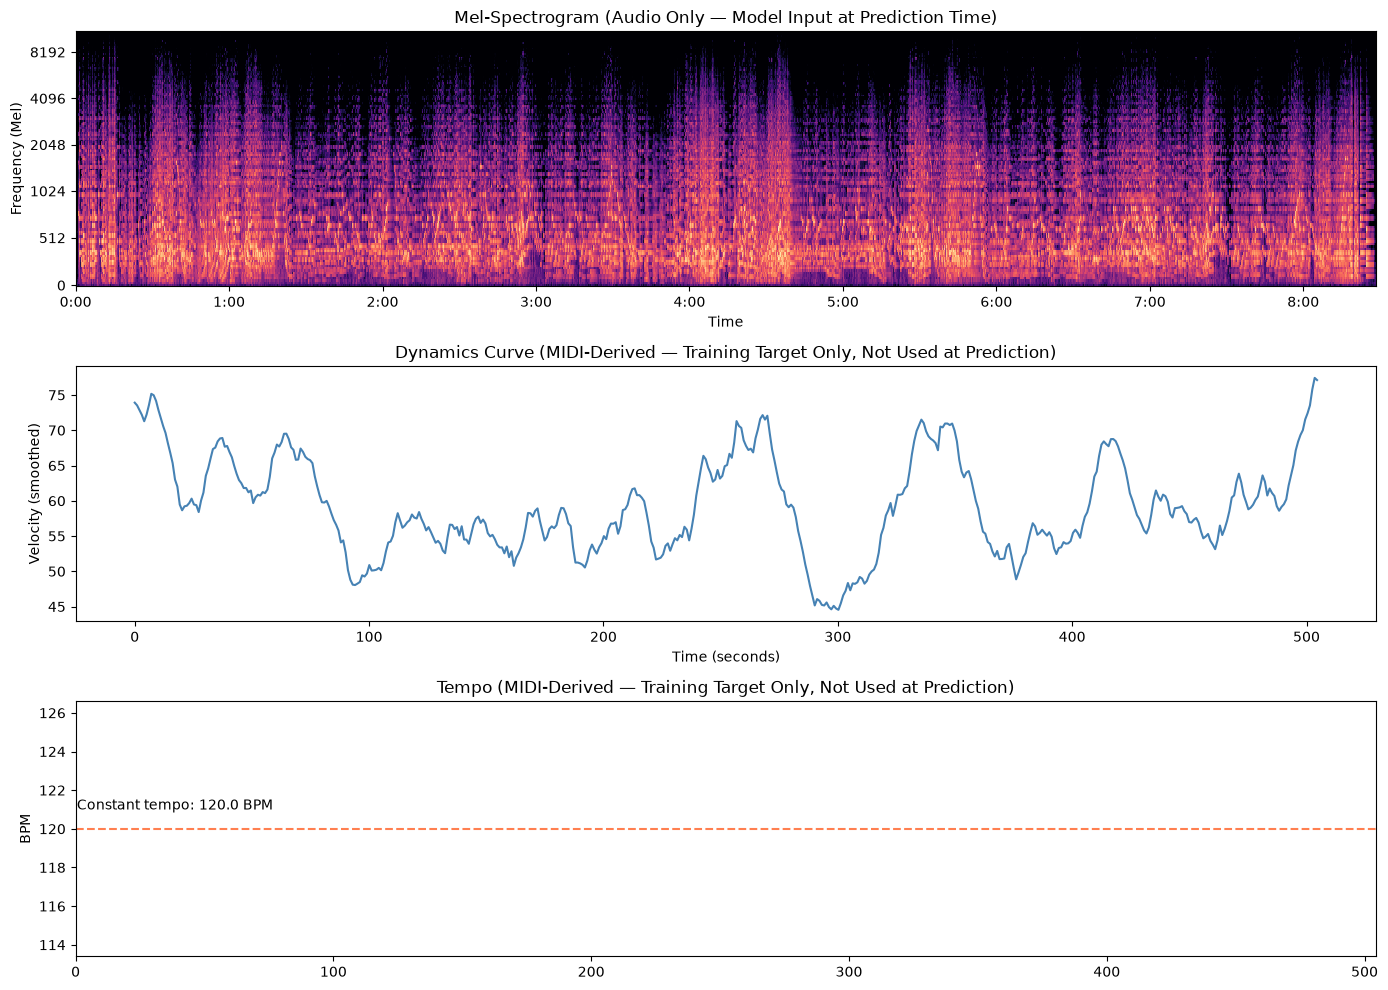


 Verification complete
  Audio shape:           (11212510,)
  Mel-spectrogram shape: (128, 21900)
  Dynamics points:       500
  Tempo entries:         1

The audio (mel-spectrogram) is the ONLY input the model
will use at prediction time. MIDI targets are derived
during training only and are never passed to the model.


In [14]:
# Visualise both

fig, axes = plt.subplots(3, 1, figsize=(14, 10))

# Mel-spectrogram (audio only — model input)
librosa.display.specshow(
    mel_spec_db, sr=sr, hop_length=512,
    x_axis='time', y_axis='mel', ax=axes[0]
)
axes[0].set_title('Mel-Spectrogram (Audio Only — Model Input at Prediction Time)')
axes[0].set_ylabel('Frequency (Mel)')

# Dynamics curve (from MIDI — model target at training time)
axes[1].plot(time_grid, dynamics_curve, color='steelblue')
axes[1].set_title('Dynamics Curve (MIDI-Derived — Training Target Only, Not Used at Prediction)')
axes[1].set_xlabel('Time (seconds)')
axes[1].set_ylabel('Velocity (smoothed)')

# Tempo (MIDI-derived — training target only)
if len(tempo_times) > 1:
    axes[2].step(tempo_times, tempos, where='post', color='coral')
else:
    axes[2].axhline(y=tempos[0], color='coral', linestyle='--')
    axes[2].text(0.5, tempos[0]+1, f'Constant tempo: {tempos[0]:.1f} BPM', fontsize=10)
axes[2].set_title('Tempo (MIDI-Derived — Training Target Only, Not Used at Prediction)')
axes[2].set_xlim(0, times[-1])
axes[2].set_ylabel('BPM')

plt.tight_layout()
plt.savefig('maestro_verification.png', dpi=150)
plt.show()

print("\n Verification complete")
print(f"  Audio shape:           {y.shape}")
print(f"  Mel-spectrogram shape: {mel_spec_db.shape}")
print(f"  Dynamics points:       {len(dynamics_curve)}")
print(f"  Tempo entries:         {len(tempo_times)}")
print("\nThe audio (mel-spectrogram) is the ONLY input the model")
print("will use at prediction time. MIDI targets are derived")
print("during training only and are never passed to the model.")